# Laboratorio – Ingenio Providencia

## Tarea 1. Introducción y contexto del negocio

La agroindustria de la caña representa el 19,5 % del PIB agrícola y el 12,1 % del PIB industrial del Valle del Cauca (Asocaña, datos 2023), con 13 ingenios en la región.

- **TCH** depende de las lluvias, el suelo, la variedad, la edad de cosecha, el número de cortes, el riego y la fertilización. El efecto de la lluvia no es lineal: tanto el déficit como el exceso reducen el rendimiento.
- **%Sac.Caña** depende principalmente de la maduración (madurantes, semanas de maduración), la variedad y el clima de los meses previos a la cosecha.
- En la literatura, los modelos más usados para predecir rendimiento son la regresión lineal múltiple, Random Forest y Gradient Boosting.
- Para la clasificación se usarán terciles (bajo ≤ P33,3 < medio ≤ P66,7 < alto).

El desarrollo completo está en `Docs/Taller.pdf` y en el informe.

## Tarea 2. Análisis exploratorio de datos (EDA) y preprocesamiento

En esta parte la idea es comprender cómo están estructurados los datos de los datasets que tenemos como recursos y además la calidad de los mismos.
Se analizarán los valores faltantes, las distribuciones de las variables, los posibles valores atípicos y las relaciones entre los predictores y las variables objetivo.

Se trabajará con dos datasets: HISTORICO_SUERTES.xlsx, para explorar la predicción de TCH y del porcentaje de sacarosa mediante regresión, y BD_IPSA_1940.xlsx, para preparar las variables destinadas a los modelos de clasificación.

### 2.1 Configuración inicial

Por si acaso, como uso conda en mi portátil Linux, tuve que instalar estas librerías (dependiendo de la manera en la que tengas instalado jupyter el comando puede variar): %pip install pandas numpy matplotlib seaborn openpyxl scikit-learn statsmodels


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

### 2.2 Carga de datos

Para cargar los datasets y mantener una estructura coherente con el repositorio, se usa una ruta relativa a la carpeta `Data`.

In [2]:
import pandas as pd
from pathlib import Path

# Carpeta donde se encuentran los datasets, Lo busca para que no tengamos problemas en el repo
ruta_datos = Path("Data")

# Cargar los archivos Excel
historico = pd.read_excel(ruta_datos / "HISTORICO_SUERTES.xlsx")
ipsa = pd.read_excel(ruta_datos / "BD_IPSA_1940.xlsx")

# Verificar que se cargaron correctamente
print("Dimensiones de HISTORICO_SUERTES:", historico.shape)
print("Dimensiones de BD_IPSA_1940:", ipsa.shape)

display(historico.head())
display(ipsa.head())

Dimensiones de HISTORICO_SUERTES: (21027, 85)
Dimensiones de BD_IPSA_1940: (2187, 21)


,Período,Hacienda,Nombre,Zona,Tenencia,Suerte,Suelo,Area Neta,Dist Km,Variedad,Cod.Estado #,Cod.Estado,F.Siembra,D.S.,Ult.Riego,Edad Ult Cos,F.Ult.Corte,Destino 1=Semilla,Cod. T.Cultivo,Cultivo,Fec.Madur.,Producto,Dosis Madurante,Semanas mad.,TonUltCorte,TCH,TCHM,Ton.Azucar,Rdto,TAH,TAHM,Sac.Caña Precosecha,Edad.Precosecha,%Sac.Caña,%Sac.Muestreadora,%ATR,KATRHM,%Fibra Caña,%AR Jugo,%ME Min,%ME Veg,%ME Tot,Brix,Pureza,Vejez,Tipo Quema,T.Corte,Cerca de,Cosechó,Num.Riegos,M3 Riego,DDUlt.Riego,Lluvias (2 Meses Ant.),Lluvias Ciclo,Lluvias 0 -3,Lluvias tres a seis,Lluvias seis a nueve,Luvias 9 -FC,%Infest.Diatrea,Fosfato Jugo,Fert.Nitrogen.,Urea 46%,MEZ,Boro Granul.,MicroZinc,NITO_XTEND,Sul.Amonio,NITRAX-S,Vinaza,Codigo Estacion,Temp. Media 0-3,Temp. Media Ciclo,Temp Max Ciclo,Temp Min Ciclo,Humedad Rel Media 0-3,Humedad Rel Media Ciclo,Oscilacion Temp Med 0-3,Oscilacion Temp Ciclo,Sum Oscilacion Temp Ciclo,Radicion Solar 0-3,Radiacion Solar Ciclo,Precipitacion 0_3,Precipitacion Ciclo,Evaporacion 0-3,Evaporacion Ciclo
0,201701,80493,LA CONCHA,IP02,51.0,002A,CANTARINA,6.00,4.3,CC85-92,5,Corte 5,2010-08-20,NaN,NaT,12.81,2017-01-02,0,1.0,Normal,2016-11-04,BONUS 250 EC REGULADOR FISIOLÓGICO,1.0,8.428571,727.19,121.198333,9.461228,86.050,11.8332,14.341666,1.119567,16.8172,NaN,13.7582,13.508,15.1653,1434.823641,16.910,0.84,0.355,10.198,10.553,15.7464,87.2241,2.735,VERDE,MECANIZADO,El Cerrito,AI08,NaN,0.0,0,258.0,1038.0,0.0,454.0,102.0,482.0,NaN,178.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,201701,81284,UKRANIA INCAUCA,IP05,81.0,039B,NaN,1.45,NaN,CC85-92,5,Corte 5,2011-01-27,NaN,NaT,11.14,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,136.00,93.793103,8.419488,14.728,10.8294,10.157241,0.911781,NaN,NaN,12.8430,12.551,14.0410,1182.180399,16.936,0.55,2.298,7.273,9.571,15.2240,84.3602,73.823,Q.ACCIDENTAL,MANUAL,Candelaria,AI08,NaN,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,382.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,201701,80203,EL AMPARO SAA,IP05,31.0,007,CORINTIAS,8.24,23.0,CC01-1228,4,Corte 4,2011-10-25,1.65,2016-09-17,12.32,2017-01-02,0,1.0,Normal,2016-11-04,BONUS 250 EC REGULADOR FISIOLÓGICO,1.1,8.428571,1436.62,174.347087,14.151549,145.268,10.1117,17.629611,1.430974,14.7749,12.02,11.9364,11.940,13.1236,1857.192723,15.512,0.61,3.000,9.323,12.323,14.1130,84.4527,2.108,VERDE,MECANIZADO,Palmira,AI08,5.0,48513.6,107,246.0,1002.0,106.0,326.0,113.0,457.0,NaN,226.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,201701,81380,SAN JUDAS INCAUCA,IP05,82.0,013A,NaN,1.05,66.5,CC01-1940,2,Corte 2,2014-03-08,NaN,NaT,9.79,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,143.63,136.790476,13.972469,13.517,9.4109,12.873333,1.314947,NaN,NaN,11.2770,10.931,12.4820,1744.043640,17.621,0.67,0.140,6.788,6.927,13.6350,82.7062,64.614,Q.ACCIDENTAL,MANUAL,Corinto,AI08,NaN,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,278.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,201701,80298,JAVA,IP06,31.0,025A,GALPON,4.53,17.0,RB73-2223,3,Corte 3,2013-01-10,1.65,NaT,11.53,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,512.20,113.068432,9.806455,42.505,8.2985,9.383002,0.813790,16.7662,NaN,10.2160,10.294,11.6030,1137.843039,14.352,0.95,0.592,2.939,3.531,12.9760,78.7299,71.021,Q.ACCIDENTAL,MANUAL,Guacari,AI08,NaN,0.0,0,138.0,991.0,264.0,255.0,188.0,284.0,NaN,244.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Unnamed: 0,NOME,FAZ,TAL,tipocorte,variedad,madurada,producto,dosismad,semsmad,edad,cortes,me,vejez,sacarosa,mes,periodo,TCH,lluvias,grupo_tenencia,pct_diatrea
0,11,AMAIME SILCA,81291,40,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,8.3,12.3,4,12.7,2.4,14.0,12,202012,112,137,3,6.2
1,12,AMAIME SILCA,81291,41,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,6.3,11.2,2,7.8,2.3,13.0,3,201903,157,0,3,3.5
2,13,AMAIME SILCA,81291,41,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.6,7.9,12.2,3,8.8,1.8,13.3,3,202003,167,68,3,4.3
3,15,AMAIME SILCA,81291,43,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,6.6,13.1,1,6.1,2.5,13.4,3,201903,156,0,3,3.5
4,16,AMAIME SILCA,81291,43,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.6,8.1,12.2,2,7.9,2.1,14.0,3,202003,151,68,3,4.3


### 2.3 Estructura de los datasets

In [3]:
print("=== HISTORICO_SUERTES ===")
historico.info()
print(historico.columns.tolist())

print("\n=== BD_IPSA_1940 ===")
ipsa.info()
print(ipsa.columns.tolist())

=== HISTORICO_SUERTES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21027 entries, 0 to 21026
Data columns (total 85 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Período                    21027 non-null  int64         
 1   Hacienda                   21027 non-null  int64         
 2   Nombre                     21027 non-null  object        
 3   Zona                       21027 non-null  object        
 4   Tenencia                   21026 non-null  float64       
 5   Suerte                     21027 non-null  object        
 6   Suelo                      17269 non-null  object        
 7   Area Neta                  21027 non-null  float64       
 8   Dist Km                    21022 non-null  float64       
 9   Variedad                   21027 non-null  object        
 10  Cod.Estado #               21027 non-null  int64         
 11  Cod.Estado                 21027 non-null

In [4]:
print("Columnas de HISTORICO_SUERTES:")
print(historico.columns.tolist())

print("\nColumnas de BD_IPSA_1940:")
print(ipsa.columns.tolist())

Columnas de HISTORICO_SUERTES:
['Período', 'Hacienda', 'Nombre', 'Zona', 'Tenencia', 'Suerte', 'Suelo', 'Area Neta', 'Dist Km', 'Variedad', 'Cod.Estado #', 'Cod.Estado', 'F.Siembra', 'D.S.', 'Ult.Riego', 'Edad Ult Cos', 'F.Ult.Corte', 'Destino 1=Semilla', 'Cod. T.Cultivo', 'Cultivo', 'Fec.Madur.', 'Producto', 'Dosis Madurante', 'Semanas mad.', 'TonUltCorte', 'TCH', 'TCHM', 'Ton.Azucar', 'Rdto', 'TAH', 'TAHM', 'Sac.Caña Precosecha', 'Edad.Precosecha', '%Sac.Caña', '%Sac.Muestreadora', '%ATR', 'KATRHM', '%Fibra Caña', '%AR Jugo', '%ME Min', '%ME Veg', '%ME Tot', 'Brix', 'Pureza', 'Vejez', 'Tipo Quema', 'T.Corte', 'Cerca de', 'Cosechó', 'Num.Riegos', 'M3 Riego', 'DDUlt.Riego', 'Lluvias (2 Meses Ant.)', 'Lluvias Ciclo', 'Lluvias 0 -3', 'Lluvias tres a seis', 'Lluvias seis a nueve', 'Luvias 9 -FC', '%Infest.Diatrea', 'Fosfato Jugo', 'Fert.Nitrogen.', 'Urea 46%', 'MEZ', 'Boro Granul.', 'MicroZinc', 'NITO_XTEND', 'Sul.Amonio', 'NITRAX-S', 'Vinaza', 'Codigo Estacion', 'Temp. Media 0-3', 'Temp.

### 2.4 Calidad de los datos

Se evaluarán ambos datasets mediante el porcentaje de valores faltantes, la cantidad de filas duplicadas, las variables constantes y las columnas que podrían funcionar como identificadores.

Estos aspectos son importantes porque una variable con demasiados datos ausentes puede limitar su utilidad, mientras que una variable constante no permite diferenciar los registros. Las decisiones de eliminación o imputación se tomarán considerando también la relevancia agronómica de cada variable.

#### 2.4.1 Porcentaje de valores nulos

In [5]:
#Adaptado del taller de Scouting
def analizar_faltantes(df, nombre):
    resultado = pd.DataFrame({
        "Valores nulos": df.isna().sum(),
        "Porcentaje nulo": df.isna().mean() * 100,
        "Tipo de dato": df.dtypes.astype(str),
        "Valores únicos": df.nunique(dropna=True)})

    resultado = resultado.sort_values("Porcentaje nulo", ascending=False)
    print(f"\nDataset: {nombre}")
    display(resultado.round(2))
    return resultado

faltantes_historico = analizar_faltantes(historico, "HISTORICO_SUERTES")

faltantes_ipsa = analizar_faltantes(ipsa, "BD_IPSA_1940")


Dataset: HISTORICO_SUERTES


,Valores nulos,Porcentaje nulo,Tipo de dato,Valores únicos
Sum Oscilacion Temp Ciclo,21027,100.00,float64,0
Fert.Nitrogen.,21027,100.00,float64,0
Urea 46%,20304,96.56,float64,413
NITRAX-S,20279,96.44,float64,430
MEZ,20056,95.38,float64,73
MicroZinc,19878,94.54,float64,70
Boro Granul.,19742,93.89,float64,76
Sul.Amonio,19670,93.55,float64,246
NITO_XTEND,17348,82.50,float64,313
Vinaza,16929,80.51,float64,2706



Dataset: BD_IPSA_1940


,Valores nulos,Porcentaje nulo,Tipo de dato,Valores únicos
Unnamed: 0,0,0.0,int64,2187
NOME,0,0.0,object,285
FAZ,0,0.0,int64,285
TAL,0,0.0,object,273
tipocorte,0,0.0,object,1
variedad,0,0.0,object,1
madurada,0,0.0,object,1
producto,0,0.0,object,1
dosismad,0,0.0,float64,18
semsmad,0,0.0,float64,150


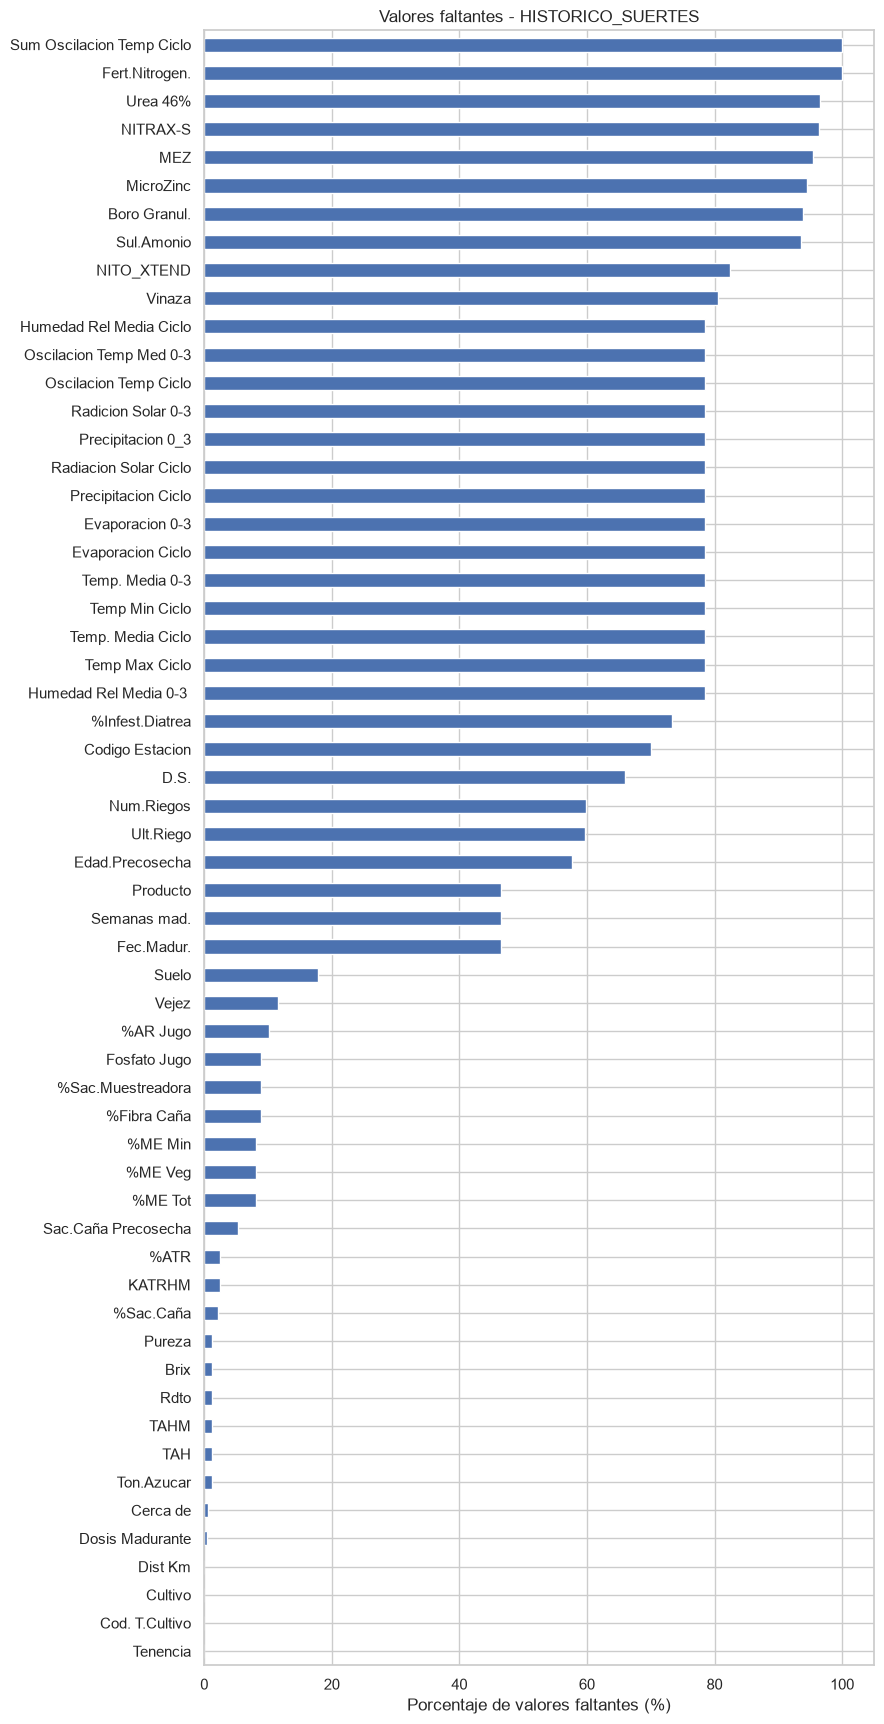

BD_IPSA_1940: no hay valores nulos.


In [6]:
def graficar_faltantes(df, nombre):
    porcentajes = df.isna().mean().mul(100)
    porcentajes = porcentajes[porcentajes > 0].sort_values()

    if porcentajes.empty:
        print(f"{nombre}: no hay valores nulos.")
        return

    porcentajes.plot(
        kind="barh",
        figsize=(9, max(4, len(porcentajes) * 0.3))
    )
    plt.xlabel("Porcentaje de valores faltantes (%)")
    plt.title(f"Valores faltantes - {nombre}")
    plt.tight_layout()
    plt.show()

graficar_faltantes(historico, "HISTORICO_SUERTES")
graficar_faltantes(ipsa, "BD_IPSA_1940")

#### 2.4.2 Duplicados y tipos de dato

In [7]:
def revisar_calidad(df, nombre):
    resumen = pd.DataFrame({
        "Tipo": df.dtypes.astype(str),
        "Faltantes": df.isna().sum(),
        "% faltantes": df.isna().mean() * 100,
        "Valores únicos": df.nunique()
    })

    resumen["% faltantes"] = resumen["% faltantes"].round(2)

    print(f"\nCalidad de datos: {nombre}")
    print("Filas duplicadas:", df.duplicated().sum())
    display(resumen.sort_values("% faltantes", ascending=False))

revisar_calidad(historico, "HISTORICO_SUERTES")
revisar_calidad(ipsa, "BD_IPSA_1940")


Calidad de datos: HISTORICO_SUERTES
Filas duplicadas: 0


,Tipo,Faltantes,% faltantes,Valores únicos
Sum Oscilacion Temp Ciclo,float64,21027,100.00,0
Fert.Nitrogen.,float64,21027,100.00,0
Urea 46%,float64,20304,96.56,413
NITRAX-S,float64,20279,96.44,430
MEZ,float64,20056,95.38,73
MicroZinc,float64,19878,94.54,70
Boro Granul.,float64,19742,93.89,76
Sul.Amonio,float64,19670,93.55,246
NITO_XTEND,float64,17348,82.50,313
Vinaza,float64,16929,80.51,2706



Calidad de datos: BD_IPSA_1940
Filas duplicadas: 0


,Tipo,Faltantes,% faltantes,Valores únicos
Unnamed: 0,int64,0,0.0,2187
NOME,object,0,0.0,285
FAZ,int64,0,0.0,285
TAL,object,0,0.0,273
tipocorte,object,0,0.0,1
variedad,object,0,0.0,1
madurada,object,0,0.0,1
producto,object,0,0.0,1
dosismad,float64,0,0.0,18
semsmad,float64,0,0.0,150


#### 2.4.3 Columnas vacías, constantes e identificadores

In [8]:
def variables_constantes(df):
    return [col for col in df.columns
        if df[col].nunique(dropna=True) <= 1]


print("Constantes en el histórico:")
print(variables_constantes(historico))

print("\nConstantes en IPSA:")
print(variables_constantes(ipsa))

Constantes en el histórico:
['Fert.Nitrogen.', 'Sum Oscilacion Temp Ciclo']

Constantes en IPSA:
['tipocorte', 'variedad', 'madurada', 'producto']


In [9]:
print("Columnas completamente vacías:")
print(historico.columns[historico.isna().all()].tolist())

print("\nPosibles identificadores en IPSA:")
display(ipsa[["Unnamed: 0", "NOME", "FAZ", "TAL"]].head())

Columnas completamente vacías:
['Fert.Nitrogen.', 'Sum Oscilacion Temp Ciclo']

Posibles identificadores en IPSA:


,Unnamed: 0,NOME,FAZ,TAL
0,11,AMAIME SILCA,81291,40
1,12,AMAIME SILCA,81291,41
2,13,AMAIME SILCA,81291,41
3,15,AMAIME SILCA,81291,43
4,16,AMAIME SILCA,81291,43


Según los resultados, las columnas completamente vacías del histórico son Fert.Nitrogen. y Sum Oscilacion Temp Ciclo. En IPSA, tipocorte, variedad, madurada y producto son constantes. Las primeras dos pueden excluirse del análisis actual; las constantes de IPSA no aportan información predictiva en este archivo.

El histórico presenta una cantidad importante de valores faltantes en algunas variables de fertilización y clima. Las columnas completamente vacías no aportan información y se excluirán de la copia de trabajo. Las demás variables con muchos faltantes se evaluarán individualmente antes de decidir si se eliminan o se conservan.

En el dataset IPSA no se detectaron valores faltantes en el resumen inicial. Sin embargo, se identificaron variables constantes que no aportan capacidad para distinguir las observaciones. También se revisarán las columnas que parecen identificadores antes de decidir su tratamiento.

### 2.5 Copias de trabajo para el EDA

Con el fin de no trabajar con los datasets originales, se hacen unas copias para la realización del EDA.
En estos nuevos datasets se toman las decisiones importantes sobre el diseño y la comprensión del proyecto; de esta manera se excluyen los datos o columnas que se identificaron como no útiles.

In [10]:
historico_eda = historico.drop(
    columns=["Fert.Nitrogen.","Sum Oscilacion Temp Ciclo"],errors="ignore").copy()
#Preguntar profe: Unnamed: 0 se excluye inicialmente porque parece un índice importado?
ipsa_eda = ipsa.drop(
    columns=["Unnamed: 0", "tipocorte","variedad","madurada","producto"],errors="ignore").copy()

print("Dimensiones del histórico:", historico_eda.shape)
print("Dimensiones de IPSA:", ipsa_eda.shape)

Dimensiones del histórico: (21027, 83)
Dimensiones de IPSA: (2187, 16)


In [11]:
# Revisar columnas constantes de IPSA
columnas_constantes = [
    col for col in ipsa_eda.columns
    if ipsa_eda[col].nunique(dropna=False) <= 1
]

print("Columnas constantes en IPSA:", columnas_constantes)

# Eliminar columnas constantes porque no ayudan a distinguir registros
ipsa_eda = ipsa_eda.drop(columns=columnas_constantes)

print("Dimensiones del histórico:", historico_eda.shape)
print("Dimensiones de IPSA:", ipsa_eda.shape)

Columnas constantes en IPSA: []
Dimensiones del histórico: (21027, 83)
Dimensiones de IPSA: (2187, 16)


Las columnas constantes se eliminan porque no permiten diferenciar unas observaciones de otras. Esto no implica eliminar las columnas que identifican haciendas o suertes sin antes determinar si son necesarias para agrupar los datos o separar entrenamiento y prueba.

### 2.6 Análisis univariado

Se estudiará la distribución individual de las variables numéricas mediante estadísticas descriptivas, histogramas y diagramas de caja. Esto permite identificar asimetrías, concentraciones de valores, posibles errores y observaciones extremas.

Los valores atípicos no se eliminarán automáticamente: primero se verificará si son errores de registro o valores posibles dentro del proceso agrícola.

In [12]:
print("Estadísticas de las variables numéricas del histórico:")
display(historico_eda.describe().T)

print("Estadísticas de las variables numéricas de IPSA:")
display(ipsa_eda.describe().T)

Estadísticas de las variables numéricas del histórico:


,count,mean,min,25%,50%,75%,max,std
Período,21027.0,202039.708708,201701.0,201812.0,202010.0,202209.0,202407.0,216.642895
Hacienda,21027.0,80679.334427,80100.0,80247.0,80453.0,81104.0,82557.0,590.03015
Tenencia,21026.0,46.44873,11.0,31.0,51.0,51.0,91.0,21.513498
Area Neta,21027.0,8.642948,0.004,3.31,7.0,12.075,65.0,7.049533
Dist Km,21022.0,25.311806,1.1,12.0,21.9,32.7,155.0,18.237344
Cod.Estado #,21027.0,4.261806,0.0,1.0,3.0,6.0,31.0,4.111935
F.Siembra,21027,2015-03-11 18:18:44.839492096,1986-04-30 00:00:00,2013-03-13 00:00:00,2015-11-10 00:00:00,2018-08-07 00:00:00,2023-09-08 00:00:00,NaN
Ult.Riego,8470,2020-02-16 21:24:26.351829760,2016-01-12 00:00:00,2018-03-07 00:00:00,2019-08-14 00:00:00,2022-05-19 00:00:00,2024-06-27 00:00:00,NaN
Edad Ult Cos,21027.0,13.01111,1.31,11.93,12.62,13.86,78.19,1.97907
F.Ult.Corte,21027,2020-10-27 09:01:09.339420672,2017-01-02 00:00:00,2018-12-14 00:00:00,2020-10-11 00:00:00,2022-09-25 00:00:00,2024-07-10 00:00:00,NaN


Estadísticas de las variables numéricas de IPSA:


,count,mean,std,min,25%,50%,75%,max
FAZ,2187.0,80588.332876,572.818299,80100.0,80222.0,80396.0,80660.0,82519.0
dosismad,2187.0,0.993278,0.309096,0.0,0.8,1.0,1.2,9.0
semsmad,2187.0,9.164838,3.441579,-1.6,7.1,8.7,10.6,45.0
edad,2187.0,12.766118,1.117866,10.3,12.0,12.5,13.3,21.1
cortes,2187.0,2.794239,1.621195,1.0,1.0,2.0,4.0,14.0
me,2187.0,9.197759,1.574409,3.4,8.2,9.1,10.1,15.0
vejez,2187.0,4.172154,6.339255,0.2,2.1,2.6,3.3,102.9
sacarosa,2187.0,12.777732,0.854397,9.2,12.2,12.8,13.3,16.0
mes,2187.0,6.758573,3.482444,1.0,4.0,7.0,10.0,12.0
periodo,2187.0,201887.691358,131.982686,201407.0,201807.0,201908.0,202005.0,202101.0


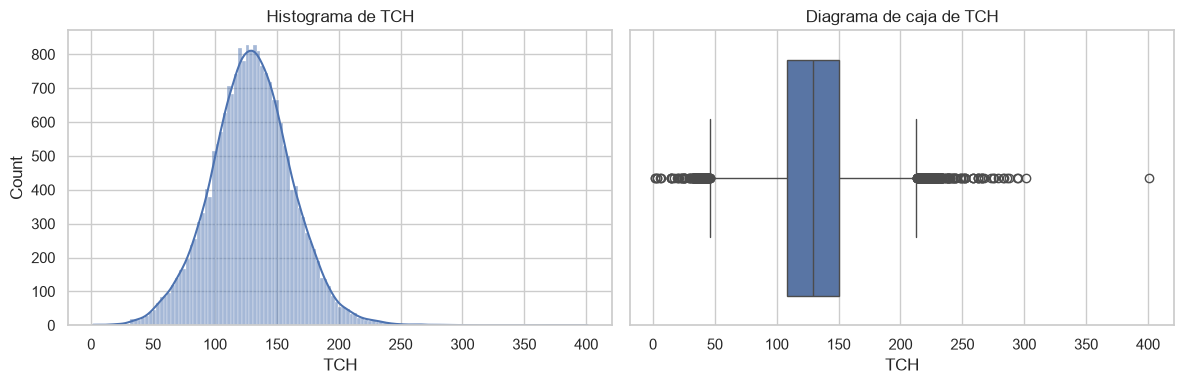

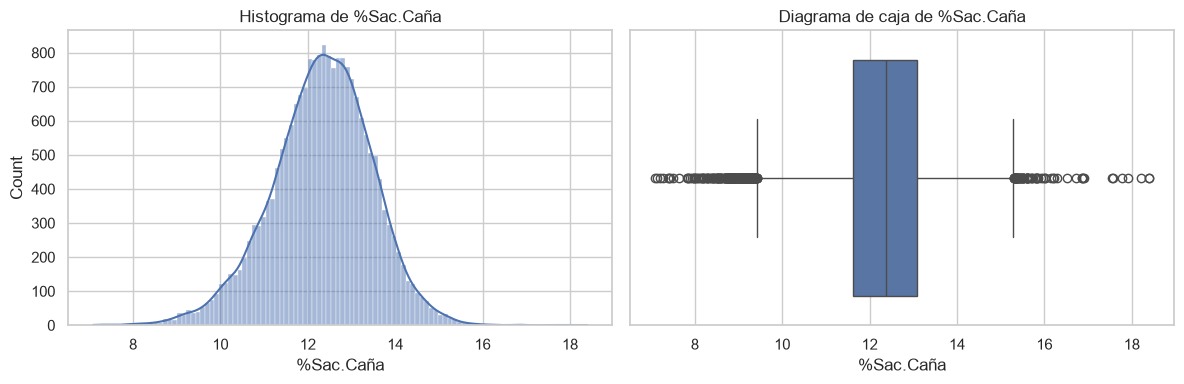

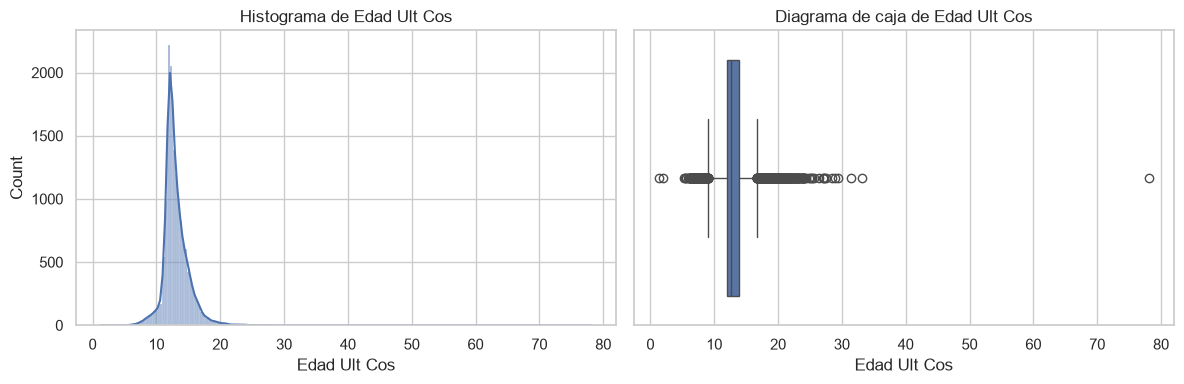

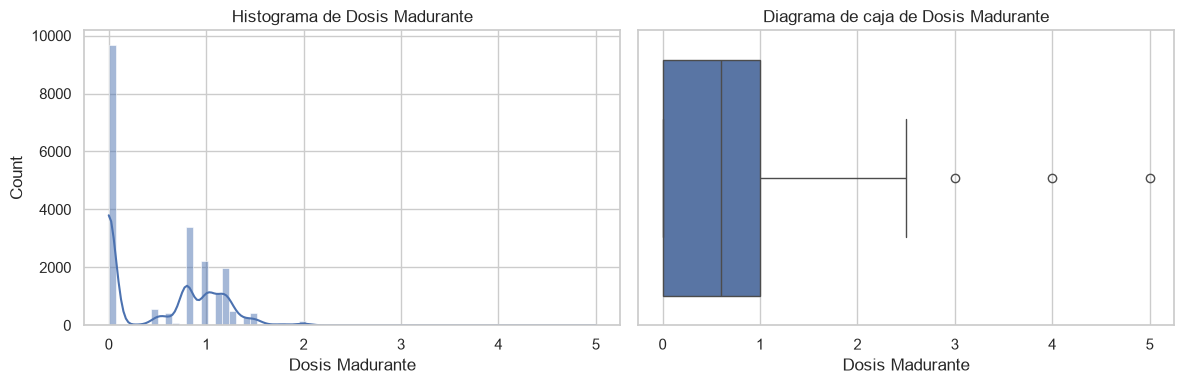

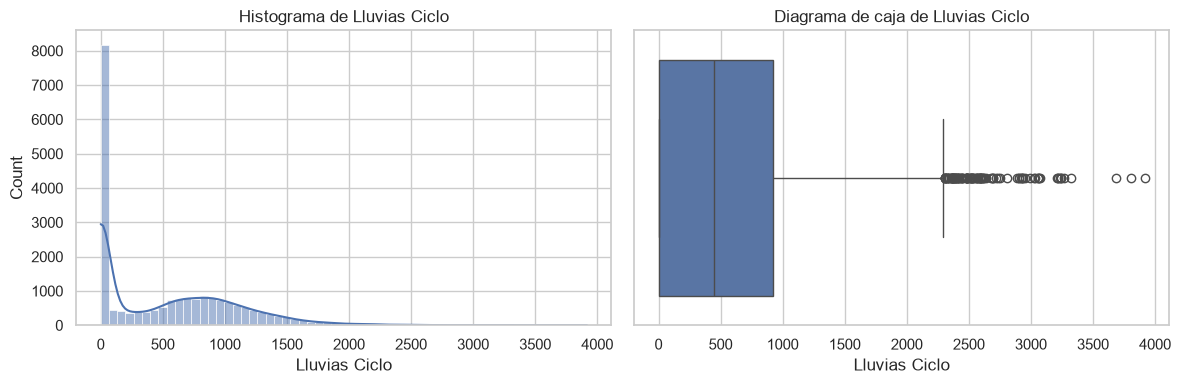

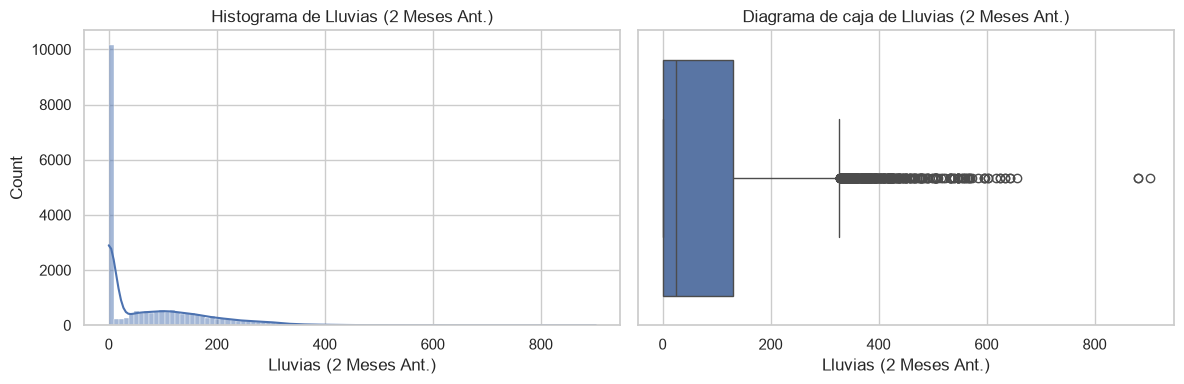

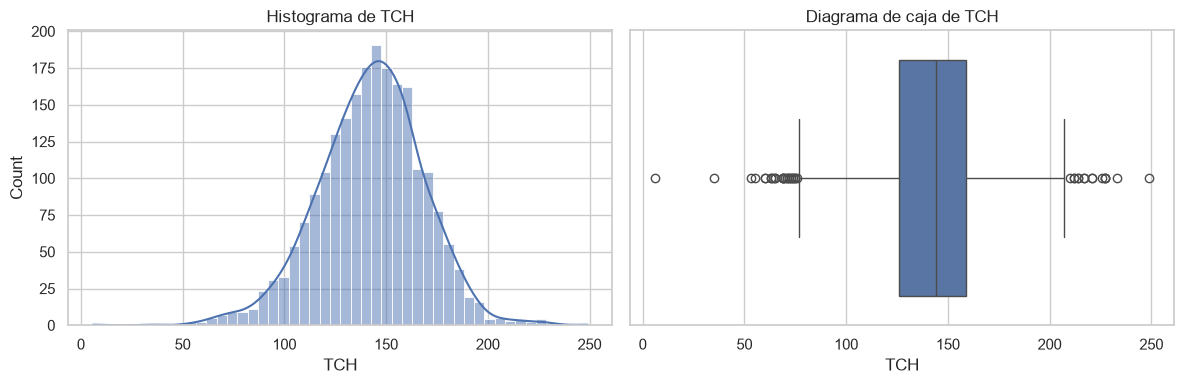

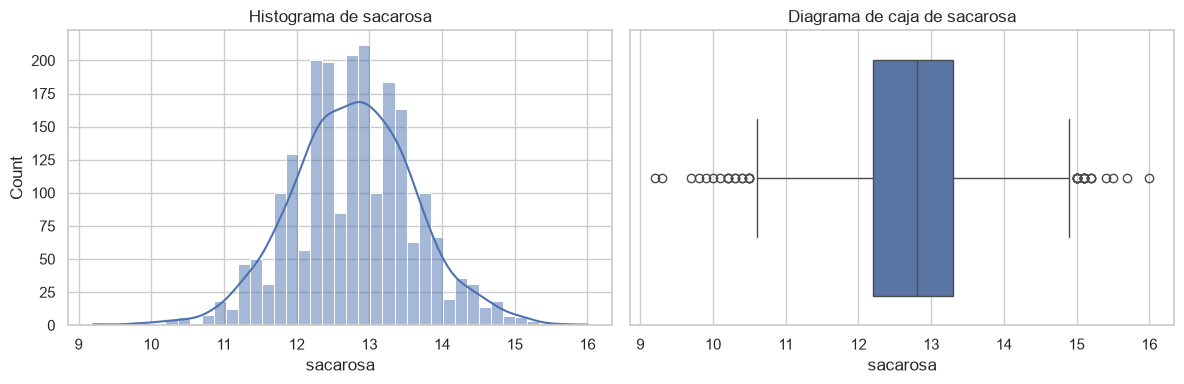

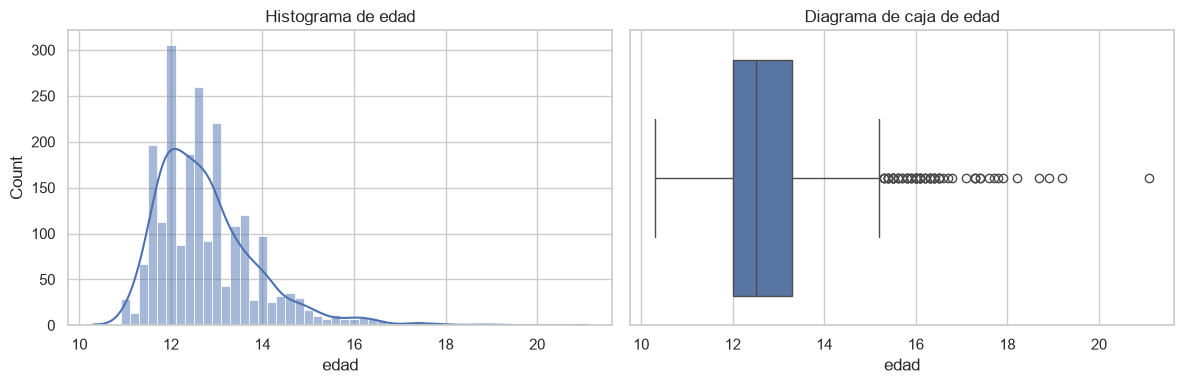

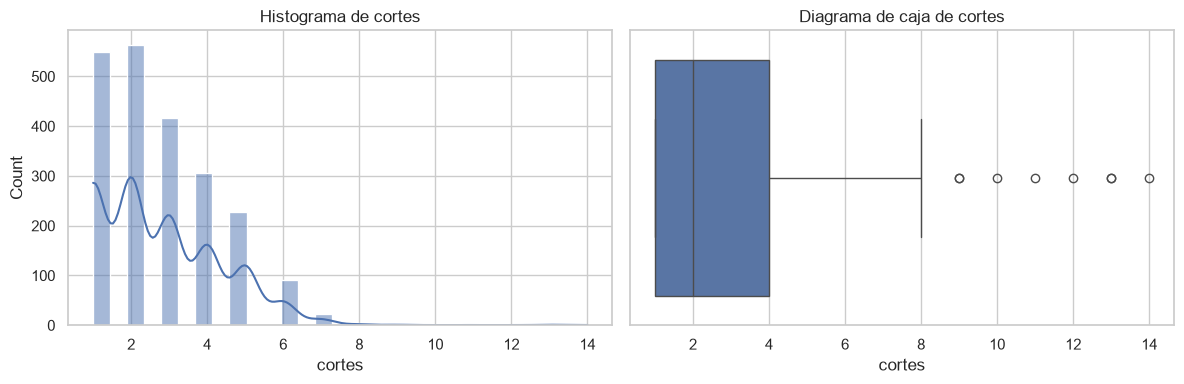

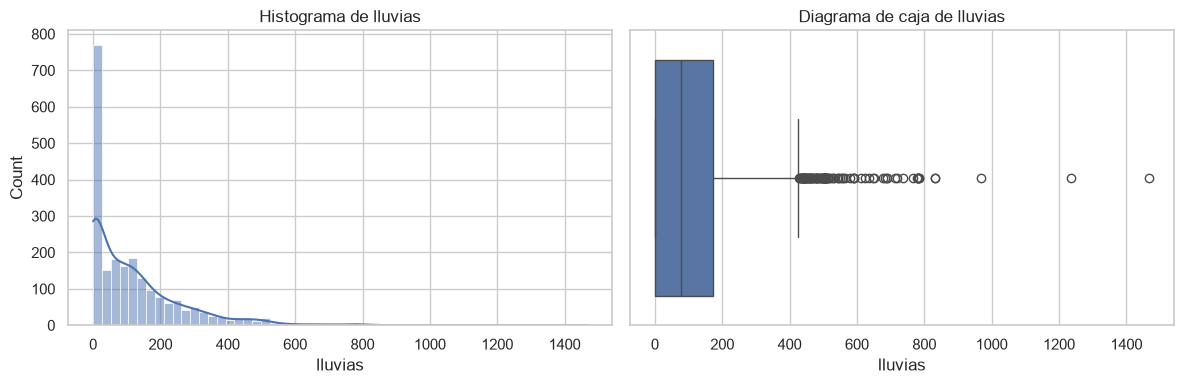

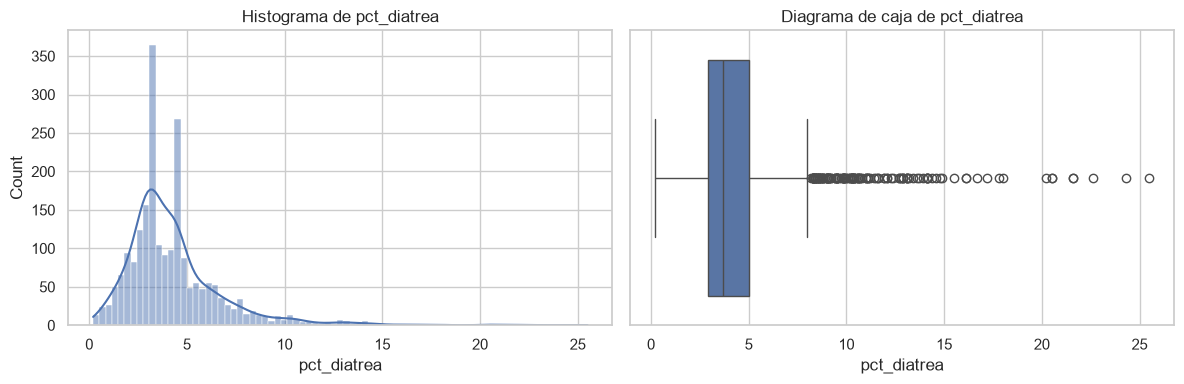

In [13]:
variables_historico = [
    "TCH",
    "%Sac.Caña",
    "Edad Ult Cos",
    "Dosis Madurante",
    "Lluvias Ciclo",
    "Lluvias (2 Meses Ant.)"
]

variables_ipsa = [
    "TCH",
    "sacarosa",
    "edad",
    "cortes",
    "lluvias",
    "pct_diatrea"
]


def analizar_distribuciones(df, columnas, nombre):
    for col in columnas:
        if col not in df.columns:
            print(f"No existe la columna: {col}")
            continue

        valores = pd.to_numeric(df[col], errors="coerce").dropna()

        if valores.empty:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        sns.histplot(valores, kde=True, ax=axes[0])
        axes[0].set_title(f"Histograma de {col}")

        sns.boxplot(x=valores, ax=axes[1])
        axes[1].set_title(f"Diagrama de caja de {col}")

        plt.tight_layout()
        plt.show()


analizar_distribuciones(
    historico_eda, variables_historico, "Histórico"
)

analizar_distribuciones(
    ipsa_eda, variables_ipsa, "IPSA"
)

### 2.7 Detección de valores inconsistentes

En las gráficas anteriores se observaron valores atípicos que es necesario revisar: valores negativos, ceros y registros que podrían estar fuera de los rangos esperados.

Estos valores no se eliminarán automáticamente: primero se identificarán para determinar si representan errores o situaciones reales.

In [14]:
# Variables que requieren una revisión inicial
variables_revision = [
    "Area Neta",
    "Edad Ult Cos",
    "Semanas mad.",
    "TCH",
    "%Sac.Caña",
    "Brix",
    "Pureza",
    "Dosis Madurante"
]

for col in variables_revision:
    if col in historico.columns:
        valores = pd.to_numeric(historico[col], errors="coerce")

        print(f"\n--- {col} ---")
        print("Valores negativos:", (valores < 0).sum())
        print("Valores iguales a cero:", (valores == 0).sum())
        print("Valores faltantes:", valores.isna().sum())


--- Area Neta ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- Edad Ult Cos ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- Semanas mad. ---
Valores negativos: 13
Valores iguales a cero: 2
Valores faltantes: 9775

--- TCH ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- %Sac.Caña ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 449

--- Brix ---
Valores negativos: 0
Valores iguales a cero: 1857
Valores faltantes: 267

--- Pureza ---
Valores negativos: 0
Valores iguales a cero: 1854
Valores faltantes: 269

--- Dosis Madurante ---
Valores negativos: 0
Valores iguales a cero: 9685
Valores faltantes: 104


In [15]:
historico.loc[
    pd.to_numeric(historico["Semanas mad."], errors="coerce") < 0,
    ["Período", "Hacienda", "Suerte", "Semanas mad."]
].head(20)

,Período,Hacienda,Suerte,Semanas mad.
3734,201805,80114,600,-1.285714
3748,201806,80114,517B,-1.142857
5223,201812,81386,001,-1.571428
7535,201910,80508,002A,-2.000000
8319,202001,80274,005,-0.428571
9799,202007,81143,002,-0.428571
11050,202012,81052,002,-0.428571
11578,202103,80108,325,-2.000000
12237,202107,82502,002,-0.714285
14808,202206,80176,001,-0.714285


### 2.8 Correlaciones iniciales con las variables objetivo

In [16]:
def correlaciones_objetivo(df, objetivo):
    datos = df.select_dtypes(include="number")

    if objetivo not in datos.columns:
        print(f"No se encontró {objetivo} como variable numérica.")
        return

    correlaciones = (
        datos.corr(method="spearman", min_periods=100)[objetivo]
        .drop(objetivo)
        .dropna()
        .sort_values(key=abs, ascending=False)
    )

    return correlaciones.to_frame("Correlación de Spearman")


correlaciones_objetivo(historico_eda, "TCH").head(15)

,Correlación de Spearman
TAH,0.895056
TCHM,0.834753
KATRHM,0.791229
TAHM,0.762748
TonUltCorte,0.340939
Ton.Azucar,0.318425
Edad Ult Cos,0.303779
Cod.Estado #,-0.291462
Evaporacion Ciclo,0.274624
%ATR,-0.192435


In [17]:
correlaciones_objetivo(ipsa_eda, "sacarosa").head(15)

,Correlación de Spearman
me,-0.285044
TCH,-0.203176
semsmad,0.177902
periodo,0.140923
mes,0.137679
pct_diatrea,-0.085545
lluvias,-0.074567
grupo_tenencia,-0.060266
vejez,-0.049188
FAZ,-0.041051


In [18]:
correlaciones_objetivo(ipsa_eda, "TCH").head(15)

,Correlación de Spearman
cortes,-0.266893
periodo,-0.235450
sacarosa,-0.203176
edad,0.153529
grupo_tenencia,0.144829
vejez,-0.102092
FAZ,0.100957
pct_diatrea,0.098559
dosismad,0.060819
me,0.016775


**Dataset IPSA.** Las correlaciones de Spearman permitieron identificar las variables con mayor asociación monotónica con las variables objetivo.

Para la sacarosa, la variable `me` presentó la asociación más alta (ρ = -0.285), seguida por `TCH` (ρ = -0.203) y `semsmad` (ρ = 0.178). Estos resultados indican que `me` y `TCH` tienden a asociarse con menores niveles de sacarosa, mientras que un mayor número de semanas de maduración se relaciona con un ligero incremento del contenido de azúcar.

En el caso de TCH, la variable `cortes` mostró la asociación más importante (ρ = -0.267), lo que sugiere que un mayor número de cortes tiende a asociarse con menores rendimientos. También se observaron asociaciones moderadas con `periodo` (ρ = -0.235) y `sacarosa` (ρ = -0.203), así como asociaciones positivas más débiles con `edad` y `grupo_tenencia`.

Aunque la mayoría de las correlaciones son bajas o moderadas, estos resultados constituyen una guía inicial para seleccionar variables candidatas. La decisión final también tendrá en cuenta el contexto agronómico, la calidad de los datos y la necesidad de evitar variables que puedan introducir fuga de información en los modelos.

### 2.9 Selección y justificación de variables

### 2.10 Tratamiento de inconsistencias y valores atípicos

### 2.11 Tratamiento de datos faltantes

### 2.12 Variables derivadas

### 2.13 Distribución y normalidad de TCH y %Sac.Caña

In [19]:
#Hay qye identificar los nombres exactos de las columnas objetivo:

### 2.14 Relaciones entre predictores y objetivos

### 2.15 Multicolinealidad (VIF)

### 2.16 Preparación de IPSA y creación de clases

### 2.17 Resumen de los datasets finales

## Tarea 3. Metodología de modelamiento

### 3.1 Regresión lineal múltiple – TCH (versión preliminar)

Primera versión del modelo de referencia, entrenada con los datos sin limpiar (R² ≈ 0.30). Se repetirá con los datos preprocesados de la Tarea 2 y con `statsmodels` para analizar los p-values.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
variables = [
    "Edad Ult Cos",
    "Variedad",
    "Suelo",
    "Dist Km",
    "Dosis Madurante",
    "Lluvias (2 Meses Ant.)",
    "Lluvias Ciclo",
    "Zona",
    "Tenencia",
    "Tipo Quema",
    "T.Corte",
    "Cod.Estado #"
]

objetivo = "TCH"

# Conservar únicamente las columnas existentes
variables = [col for col in variables if col in historico_eda.columns]

# Preparar X e y
datos_modelo = historico_eda[variables + [objetivo]].copy()
datos_modelo[objetivo] = pd.to_numeric(
    datos_modelo[objetivo], errors="coerce"
)

datos_modelo = datos_modelo.dropna(subset=[objetivo])

X = datos_modelo[variables]
y = datos_modelo[objetivo]

# Identificar variables numéricas y categóricas
numericas = X.select_dtypes(include="number").columns.tolist()
categoricas = X.select_dtypes(exclude="number").columns.tolist()

# Preprocesamiento de variables numéricas
preprocesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento de variables categóricas
preprocesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

preprocesamiento = ColumnTransformer([
    ("numericas", preprocesamiento_numerico, numericas),
    ("categoricas", preprocesamiento_categorico, categoricas)
])

# Crear el modelo
modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("regresion", LinearRegression())
])

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenar
modelo.fit(X_train, y_train)

# Evaluar
predicciones = modelo.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predicciones))
print("RMSE:", root_mean_squared_error(y_test, predicciones))
print("R²:", r2_score(y_test, predicciones))

MAE: 21.398848686550394
RMSE: 27.76372077241366
R²: 0.3056747978436638
